In [13]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [14]:
#Set time to extract historical data
years = 15
endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days = 365*years)


In [15]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [16]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate)
    adj_close_df[ticker] = data['Adj Close']
print(adj_close_df)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2008-11-20   56.466183  48.461823   73.449997   22.358795   28.019493
2008-11-21   59.512154  48.222332   78.849998   23.329775   29.609619
2008-11-24   63.635799  48.015198   80.910004   24.755623   31.373087
2008-11-25   64.107285  48.843719   80.870003   24.641907   31.810177
2008-11-26   66.584442  49.147957   80.379997   25.674122   32.985832
...                ...        ...         ...         ...         ...
2023-11-10  440.609985  69.680000  179.509995  378.390015  217.460007
2023-11-13  440.190002  6

In [17]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2008-11-21  0.052539 -0.004954  0.070942  0.042511  0.055199
2008-11-24  0.066996 -0.004305  0.025790  0.059322  0.057851
2008-11-25  0.007382  0.017108 -0.000495 -0.004604  0.013836
2008-11-26  0.037913  0.006209 -0.006078  0.041035  0.036292
2008-11-28  0.012510 -0.003166 -0.000871 -0.007867  0.012036
...              ...       ...       ...       ...       ...
2023-11-10  0.015484  0.001867 -0.010970  0.022233  0.014778
2023-11-13 -0.000954 -0.000287  0.005555 -0.003123 -0.000598
2023-11-14  0.019215  0.012128  0.008880  0.021298  0.021936
2023-11-15  0.002115 -0.005546 -0.002639  0.000752  0.002473
2023-11-16  0.001222  0.005972  0.011223  0.000855 -0.000674

[3772 rows x 5 columns]


In [29]:
#Create equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


In [30]:
#calculate historical porfolio return
historical_returns = (log_returns*weights).sum(axis=1)
print(historical_returns)

Date
2008-11-21    0.043247
2008-11-24    0.041131
2008-11-25    0.006645
2008-11-26    0.023074
2008-11-28    0.002528
                ...   
2023-11-10    0.008679
2023-11-13    0.000119
2023-11-14    0.016691
2023-11-15   -0.000569
2023-11-16    0.003720
Length: 3772, dtype: float64


In [31]:
days = 30
historical_x_day_returns = historical_returns.rolling(window=days).sum()

In [32]:
cov_matrix = log_returns.cov() * 252
portfolio_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)

In [33]:
from scipy.stats import norm

confidence_levels = [0.90, 0.95, 0.99]

VaRs = []
for cl in confidence_levels:
    VaR = portfolio_value * portfolio_std_dev * norm.ppf(cl) * np.sqrt(days / 252)
    VaRs.append(VaR)

In [34]:
print(f'{"Confidence Level":<20} {"Value at Risk":<20}')
print('-' * 40)

for cl, VaR in zip(confidence_levels, VaRs):
    print(f'{cl * 100:>6.0f}%: {"":<8} ${VaR:>10,.2f}')

Confidence Level     Value at Risk       
----------------------------------------
    90%:          $ 54,600.21
    95%:          $ 70,078.61
    99%:          $ 99,113.52


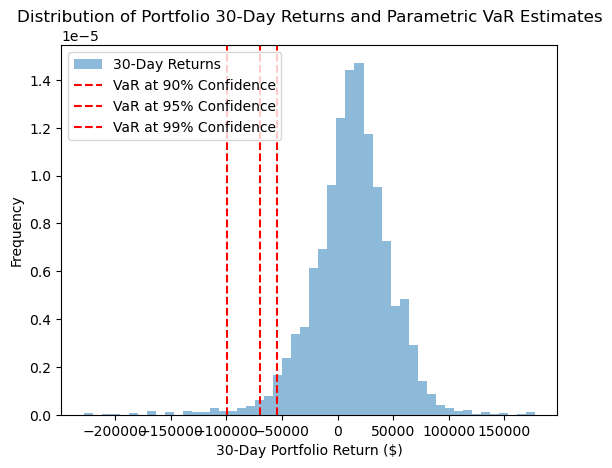

In [35]:
# Convert returns to dollar values for the histogram
historical_x_day_returns_dollar = historical_x_day_returns * portfolio_value

# Plot the histogram
plt.hist(historical_x_day_returns_dollar, bins=50, density=True, alpha=0.5, label=f'{days}-Day Returns')

# Add vertical lines representing VaR at each confidence level
for cl, VaR in zip(confidence_levels, VaRs):
    plt.axvline(x=-VaR, linestyle='--', color='r', label='VaR at {}% Confidence'.format(int(cl * 100)))

plt.xlabel(f'{days}-Day Portfolio Return ($)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {days}-Day Returns and Parametric VaR Estimates')
plt.legend()
plt.show()